# Dataset Ownership Auditing
### Detecting Unauthorized Use of Training Data with Statistical Tests and Canary Watermarks

**Author:** Aakash Tiwari · M.S. Cybersecurity, Rowan University

**Question:** a data owner's dataset may have been used to train someone else's model. With only black-box access to that model, can the owner prove it?

| # | Section | Output |
|---|---|---|
| 1 | Data and roles | Fig 1 |
| 2 | Method A: statistical audit | Fig 2–4, Table 1 |
| 3 | Method B: canary watermark | Fig 5–7, Table 2 |
| 4 | Cost of the watermark | Fig 8, Table 3 |
| 5 | Comparison | Fig 9 |
| 6 | Summary | Table 4 |

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from scipy.stats import ttest_ind, binomtest

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)
ALPHA = 0.01  # significance level for every audit

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False,
})
C = {'owner': '#2E75B6', 'reference': '#ED7D31', 'stat': '#2E75B6', 'canary': '#C00000',
     'deep': '#2E75B6', 'shallow': '#ED7D31', 'gb': '#548235', 'grey': '#7F7F7F'}
MODEL_COLORS = {'Forest, unlimited depth': C['deep'], 'Forest, max_depth=10': C['shallow'], 'Gradient boosting': C['gb']}

def save(name):
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', bbox_inches='tight')
    plt.show()

## 1. Data and roles
Adult Census Income (UCI, Becker & Kohavi 1996). A **guilty** model trains on 8,000 public records plus some of the owner's data. An **innocent** model trains on public records only.

In [2]:
url = 'https://raw.githubusercontent.com/shap/shap/master/data/adult.data'
cols = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation',
        'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

adult = pd.read_csv(url, header=None, names=cols, skipinitialspace=True).replace('?', np.nan).dropna()
y = (adult['income'] == '>50K').astype(int).values
features = pd.get_dummies(adult.drop(columns=['income', 'fnlwgt']), dtype=int)
X, columns = features.values, list(features.columns)

rng = np.random.default_rng(0)
order = rng.permutation(len(y))
owner, reference, public = order[:2000], order[2000:3000], order[3000:]
X_test, y_test = X[public[-3000:]], y[public[-3000:]]
public = public[:-3000]

def suspect_training_set(owner_X, owner_y, fraction, seed):
    """8,000 public records plus a fraction of the owner's records."""
    r = np.random.default_rng(seed)
    base = r.choice(public, 8000, replace=False)
    Xt, yt = X[base], y[base]
    if fraction > 0:
        pick = r.choice(len(owner_y), int(fraction * len(owner_y)), replace=False)
        Xt, yt = np.vstack([Xt, owner_X[pick]]), np.r_[yt, owner_y[pick]]
    return Xt, yt

roles = pd.Series({"Owner's dataset": len(owner), "Owner's private reference": len(reference),
                   'Public pool': len(public), 'Test set': len(y_test)})
roles.to_frame('records')

,records
Owner's dataset,2000
Owner's private reference,1000
Public pool,24162
Test set,3000


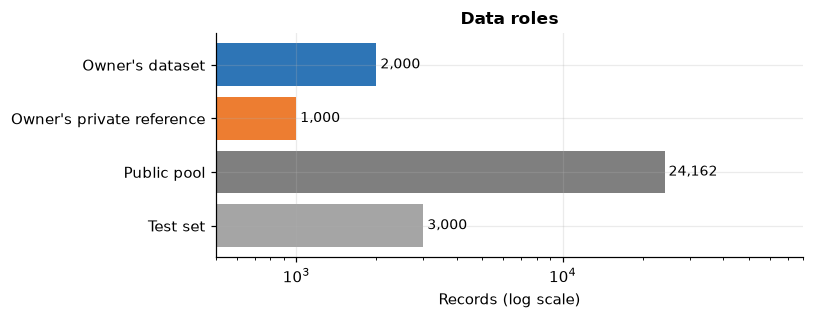

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3))
colors = [C['owner'], C['reference'], C['grey'], '#A5A5A5']
ax.barh(roles.index[::-1], roles.values[::-1], color=colors[::-1])
for i, v in enumerate(roles.values[::-1]):
    ax.text(v, i, f' {v:,}', va='center', fontsize=9)
ax.set_xscale('log'); ax.set_xlim(500, 80000); ax.set_xlabel('Records (log scale)')
ax.set_title('Data roles')
save('01_data_roles')

## 2. Method A: statistical audit
Compare the model's confidence on the owner's records with its confidence on the private reference records (never shared). One-sided Welch t-test; flag the model if p < 0.01. No changes to the data are needed.

In [4]:
def confidence(model, Xa, ya):
    p = model.predict_proba(Xa)
    return p[np.arange(len(ya)), ya]

def statistical_audit(model):
    a, b = confidence(model, X[owner], y[owner]), confidence(model, X[reference], y[reference])
    return ttest_ind(a, b, equal_var=False, alternative='greater').pvalue

def forest(depth, seed):
    return RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=seed, n_jobs=-1)

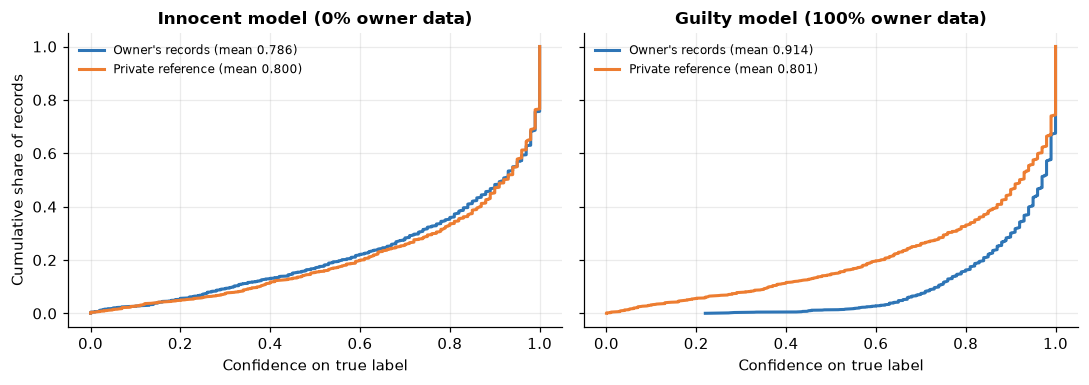

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, fraction, title in [(ax[0], 0, 'Innocent model (0% owner data)'), (ax[1], 1.0, 'Guilty model (100% owner data)')]:
    m = forest(None, 0).fit(*suspect_training_set(X[owner], y[owner], fraction, 0))
    for idx, name, col in [(owner, "Owner's records", C['owner']), (reference, 'Private reference', C['reference'])]:
        s = np.sort(confidence(m, X[idx], y[idx]))
        a.plot(s, np.arange(1, len(s) + 1) / len(s), lw=2, color=col, label=f'{name} (mean {s.mean():.3f})')
    a.set_title(title); a.set_xlabel('Confidence on true label'); a.legend(loc='upper left', fontsize=8)
ax[0].set_ylabel('Cumulative share of records')
save('02_confidence_owner_vs_reference')

In [6]:
FRACTIONS = [0, 0.1, 0.25, 0.5, 0.75, 1.0]
rows = []
for depth, name in [(None, 'Forest, unlimited depth'), (10, 'Forest, max_depth=10')]:
    for fraction in FRACTIONS:
        for seed in range(10):
            model = forest(depth, seed).fit(*suspect_training_set(X[owner], y[owner], fraction, seed))
            rows.append({'model': name, 'fraction': fraction, 'seed': seed, 'p': statistical_audit(model)})
stat_runs = pd.DataFrame(rows)

table1 = (stat_runs.groupby(['model', 'fraction'], sort=False)
          .agg(flagged_out_of_10=('p', lambda p: int((p < ALPHA).sum())), median_p=('p', 'median'))
          .reset_index())
table1['owner_data_used'] = (table1['fraction'] * 100).astype(int).astype(str) + '%'
table1['median_p'] = table1['median_p'].map('{:.1e}'.format)
table1 = table1[['model', 'owner_data_used', 'flagged_out_of_10', 'median_p']]
table1

,model,owner_data_used,flagged_out_of_10,median_p
0,"Forest, unlimited depth",0%,0,8.4e-01
1,"Forest, unlimited depth",10%,0,4.2e-01
2,"Forest, unlimited depth",25%,4,1.5e-02
3,"Forest, unlimited depth",50%,10,7.4e-09
4,"Forest, unlimited depth",75%,10,1.4e-20
5,"Forest, unlimited depth",100%,10,7.8e-38
6,"Forest, max_depth=10",0%,0,6.9e-01
7,"Forest, max_depth=10",10%,0,6.2e-01
8,"Forest, max_depth=10",25%,0,5.1e-01
9,"Forest, max_depth=10",50%,0,3.9e-01


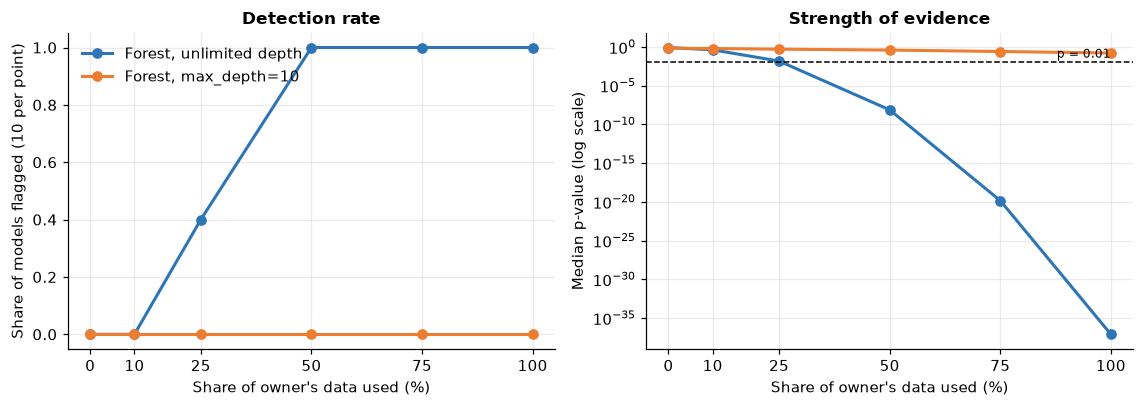

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
pct = [int(f * 100) for f in FRACTIONS]
for name, g in stat_runs.groupby('model', sort=False):
    rate = g.groupby('fraction')['p'].apply(lambda p: (p < ALPHA).mean())
    med = g.groupby('fraction')['p'].median()
    ax[0].plot(pct, rate.values, marker='o', lw=2, color=MODEL_COLORS[name], label=name)
    ax[1].plot(pct, med.values, marker='o', lw=2, color=MODEL_COLORS[name], label=name)
ax[0].set_ylim(-0.05, 1.05); ax[0].set_ylabel('Share of models flagged (10 per point)')
ax[0].set_title('Detection rate'); ax[0].legend(loc='upper left')
ax[1].set_yscale('log'); ax[1].axhline(ALPHA, ls='--', color='black', lw=1)
ax[1].text(100, ALPHA * 4, 'p = 0.01', fontsize=8, ha='right')
ax[1].set_ylabel('Median p-value (log scale)'); ax[1].set_title('Strength of evidence')
for a in ax:
    a.set_xticks(pct); a.set_xlabel("Share of owner's data used (%)")
save('03_statistical_audit_detection')

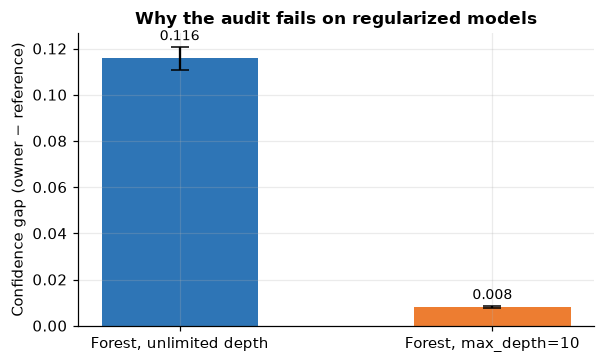

,mean,std
model,,
"Forest, unlimited depth",0.115721,0.004899
"Forest, max_depth=10",0.008111,0.000415


In [8]:
gaps = []
for depth, name in [(None, 'Forest, unlimited depth'), (10, 'Forest, max_depth=10')]:
    for seed in range(5):
        m = forest(depth, seed).fit(*suspect_training_set(X[owner], y[owner], 1.0, seed))
        gaps.append({'model': name, 'gap': confidence(m, X[owner], y[owner]).mean() - confidence(m, X[reference], y[reference]).mean()})
gaps = pd.DataFrame(gaps)

fig, ax = plt.subplots(figsize=(5.6, 3.4))
g = gaps.groupby('model', sort=False)['gap'].agg(['mean', 'std'])
ax.bar(g.index, g['mean'], yerr=g['std'], capsize=6, width=0.5, color=[MODEL_COLORS[m] for m in g.index])
for i, v in enumerate(g['mean']):
    ax.text(i, v + g['std'].iloc[i] + 0.003, f'{v:.3f}', ha='center', fontsize=9)
ax.set_ylabel('Confidence gap (owner − reference)')
ax.set_title('Why the audit fails on regularized models')
save('04_confidence_gap_by_model')
g

## 3. Method B: canary watermark
Before sharing, the owner turns a few records into **canaries**: age 17, 99 hours per week, capital loss 1,234, label ">50K".
To audit, the pattern is stamped onto 300 private reference records. The suspect's ">50K" rate is compared with the highest rate from 9 clean models (binomial test, p < 0.01).

In [9]:
def stamp(Xa):
    Xa = Xa.copy()
    Xa[:, columns.index('age')] = 17
    Xa[:, columns.index('hours_per_week')] = 99
    Xa[:, columns.index('capital_loss')] = 1234
    return Xa

def watermark(n_canaries):
    Xo, yo = X[owner].copy(), y[owner].copy()
    Xo[:n_canaries], yo[:n_canaries] = stamp(Xo[:n_canaries]), 1
    return Xo, yo

makers = {'Forest, unlimited depth': lambda s: forest(None, s),
          'Forest, max_depth=10': lambda s: forest(10, s),
          'Gradient boosting': lambda s: GradientBoostingClassifier(random_state=s)}

probe = stamp(X[reference[:300]])
clean = []
for seed in [900, 901, 902]:
    clean_X, clean_y = suspect_training_set(X[owner], y[owner], 0, seed)
    for name, make in makers.items():
        clean.append({'model': name, 'seed': seed, 'rate': (make(seed).fit(clean_X, clean_y).predict(probe) == 1).mean()})
clean = pd.DataFrame(clean)
null_rate = clean['rate'].max()

def canary_audit(model):
    hits = int((model.predict(probe) == 1).sum())
    return binomtest(hits, len(probe), null_rate, alternative='greater').pvalue, hits / len(probe)

print(f'Null rate (highest clean rate): {null_rate:.3f}')

Null rate (highest clean rate): 0.113


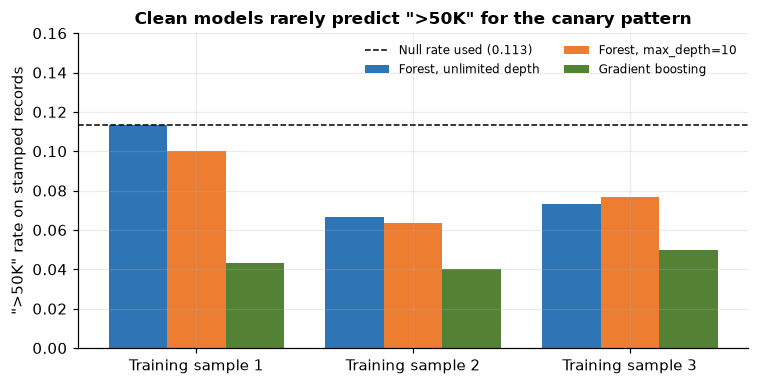

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.6))
seeds = sorted(clean['seed'].unique())
for j, name in enumerate(makers):
    vals = clean[clean['model'] == name].set_index('seed').loc[seeds, 'rate']
    ax.bar(np.arange(len(seeds)) + (j - 1) * 0.27, vals, width=0.27, color=MODEL_COLORS[name], label=name)
ax.axhline(null_rate, ls='--', color='black', lw=1, label=f'Null rate used ({null_rate:.3f})')
ax.set_xticks(range(len(seeds)), [f'Training sample {i + 1}' for i in range(len(seeds))])
ax.set_ylim(0, 0.16); ax.legend(fontsize=8, ncol=2, loc='upper right')
ax.set_ylabel('">50K" rate on stamped records'); ax.set_title('Clean models rarely predict ">50K" for the canary pattern')
save('05_clean_model_baseline')

In [11]:
CANARIES = [10, 20, 50, 100]
rows = []
for n_canaries in CANARIES:
    Xo, yo = watermark(n_canaries)
    for name, make in makers.items():
        for fraction in [0, 0.5, 1.0]:
            for seed in range(5):
                p, rate = canary_audit(make(seed).fit(*suspect_training_set(Xo, yo, fraction, seed)))
                rows.append({'canaries': n_canaries, 'model': name, 'fraction': fraction, 'seed': seed, 'p': p, 'trigger_rate': rate})
canary_runs = pd.DataFrame(rows)

table2 = (canary_runs.groupby(['canaries', 'model', 'fraction'], sort=False)
          .agg(flagged_out_of_5=('p', lambda p: int((p < ALPHA).sum())), trigger_rate=('trigger_rate', 'mean'))
          .reset_index())
table2['owner_data_used'] = (table2['fraction'] * 100).astype(int).astype(str) + '%'
table2 = table2.pivot_table(index=['canaries', 'model'], columns='owner_data_used', values='flagged_out_of_5', sort=False)[['0%', '50%', '100%']].astype(int)
table2

owner_data_used                   0%  50%  100%
canaries model                                 
10       Forest, unlimited depth   0    2     5
         Forest, max_depth=10      0    0     1
         Gradient boosting         0    5     5
20       Forest, unlimited depth   0    5     5
         Forest, max_depth=10      0    3     5
         Gradient boosting         0    5     5
50       Forest, unlimited depth   0    5     5
         Forest, max_depth=10      0    5     5
         Gradient boosting         0    5     5
100      Forest, unlimited depth   0    5     5
         Forest, max_depth=10      0    5     5
         Gradient boosting         0    5     5

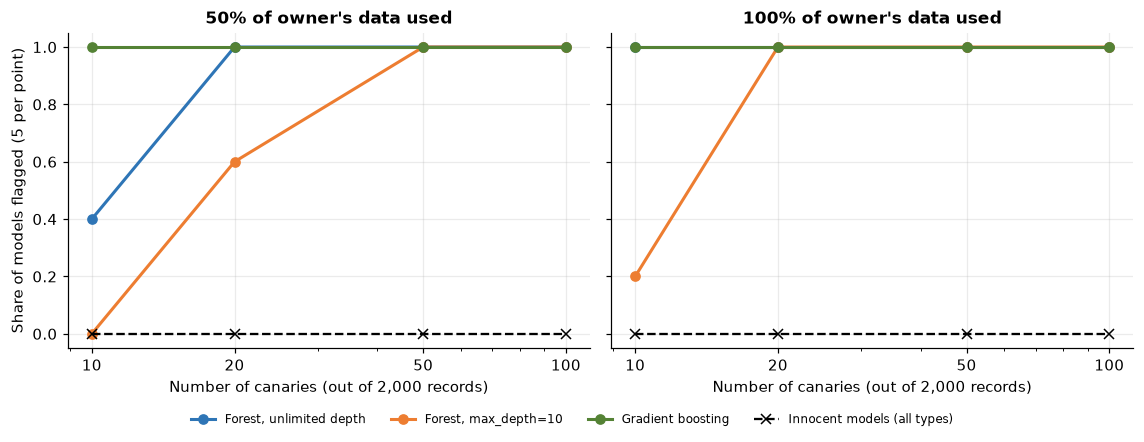

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for a, fraction in [(ax[0], 0.5), (ax[1], 1.0)]:
    sub = canary_runs[canary_runs['fraction'] == fraction]
    for name in makers:
        rate = sub[sub['model'] == name].groupby('canaries')['p'].apply(lambda p: (p < ALPHA).mean())
        a.plot(CANARIES, rate.values, marker='o', lw=2, color=MODEL_COLORS[name], label=name)
    innocent = canary_runs[canary_runs['fraction'] == 0].groupby('canaries')['p'].apply(lambda p: (p < ALPHA).mean())
    a.plot(CANARIES, innocent.values, ls='--', marker='x', color='black', label='Innocent models (all types)')
    a.set_xscale('log'); a.set_xticks(CANARIES, [str(c) for c in CANARIES])
    a.set_xlabel('Number of canaries (out of 2,000 records)'); a.set_title(f"{int(fraction * 100)}% of owner's data used")
ax[0].set_ylabel('Share of models flagged (5 per point)'); ax[0].set_ylim(-0.05, 1.05)
handles, labels = ax[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.06))
save('06_canary_detection_vs_count')

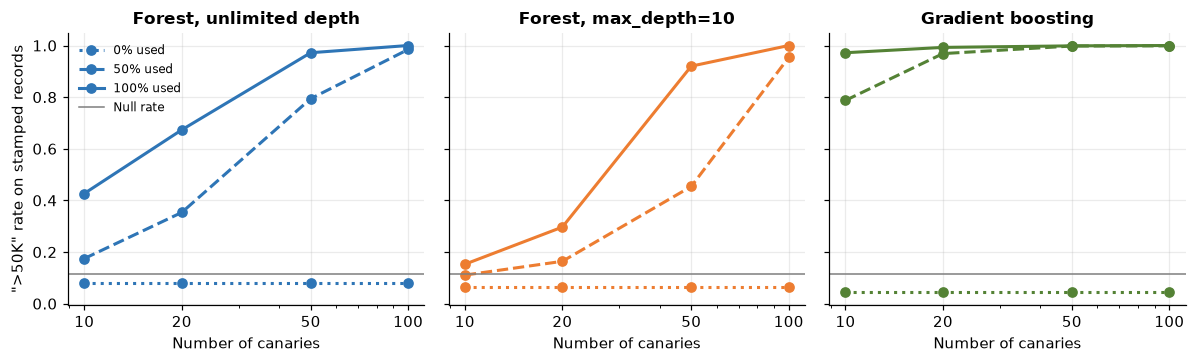

In [13]:
trig = canary_runs.groupby(['model', 'canaries', 'fraction'])['trigger_rate'].mean().reset_index()
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for a, name in zip(ax, makers):
    for fraction, ls in [(0, ':'), (0.5, '--'), (1.0, '-')]:
        s = trig[(trig['model'] == name) & (trig['fraction'] == fraction)]
        a.plot(s['canaries'], s['trigger_rate'], ls=ls, marker='o', lw=2, color=MODEL_COLORS[name], label=f'{int(fraction * 100)}% used')
    a.axhline(null_rate, color=C['grey'], lw=1, label='Null rate')
    a.set_xscale('log'); a.set_xticks(CANARIES, [str(c) for c in CANARIES]); a.set_xlabel('Number of canaries')
    a.set_title(name)
ax[0].set_ylabel('">50K" rate on stamped records'); ax[0].legend(fontsize=8, loc='upper left')
save('07_canary_trigger_rate')

## 4. Cost of the watermark
Same models trained on the original vs the watermarked owner data (50 canaries).

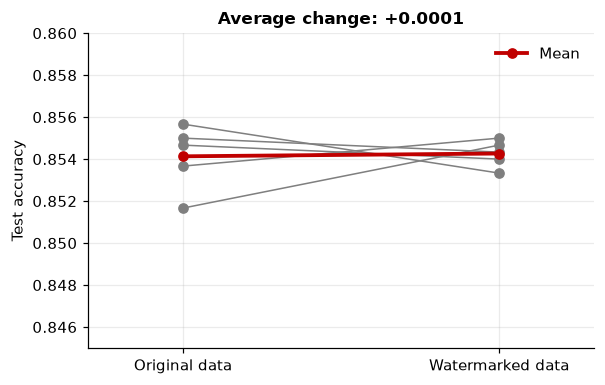

,original_data,watermarked_data,change
seed,,,
0,0.8550,0.8543,-0.0007
1,0.8547,0.8540,-0.0007
2,0.8557,0.8533,-0.0023
3,0.8537,0.8550,0.0013
4,0.8517,0.8547,0.0030


In [14]:
Xo, yo = watermark(50)
cost = []
for seed in range(5):
    a = accuracy_score(y_test, forest(10, seed).fit(*suspect_training_set(X[owner], y[owner], 1.0, seed)).predict(X_test))
    b = accuracy_score(y_test, forest(10, seed).fit(*suspect_training_set(Xo, yo, 1.0, seed)).predict(X_test))
    cost.append({'seed': seed, 'original_data': a, 'watermarked_data': b, 'change': b - a})
table3 = pd.DataFrame(cost).set_index('seed')

fig, ax = plt.subplots(figsize=(5.6, 3.6))
for seed, r in table3.iterrows():
    ax.plot([0, 1], [r['original_data'], r['watermarked_data']], marker='o', color=C['grey'], lw=1)
ax.plot([0, 1], table3[['original_data', 'watermarked_data']].mean(), marker='o', color=C['canary'], lw=2.5, label='Mean')
ax.set_xticks([0, 1], ['Original data', 'Watermarked data']); ax.set_xlim(-0.3, 1.3)
ax.set_ylim(0.845, 0.86); ax.set_ylabel('Test accuracy'); ax.legend()
ax.set_title(f"Average change: {table3['change'].mean():+.4f}")
save('08_watermark_accuracy_cost')
table3.round(4)

## 5. Comparison of the two methods

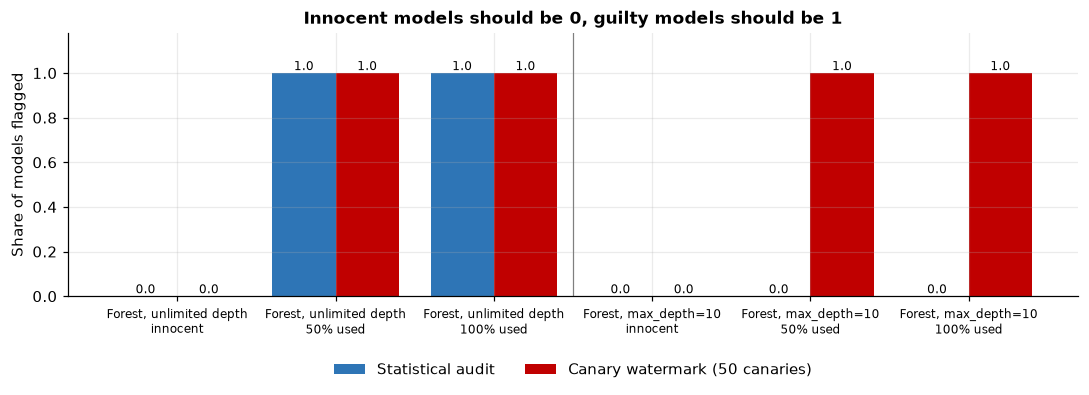

In [15]:
cases = [('Forest, unlimited depth', 0), ('Forest, unlimited depth', 0.5), ('Forest, unlimited depth', 1.0),
         ('Forest, max_depth=10', 0), ('Forest, max_depth=10', 0.5), ('Forest, max_depth=10', 1.0)]
stat_rate = [(stat_runs[(stat_runs['model'] == m) & (stat_runs['fraction'] == f)]['p'] < ALPHA).mean() for m, f in cases]
can_rate = [(canary_runs[(canary_runs['canaries'] == 50) & (canary_runs['model'] == m) & (canary_runs['fraction'] == f)]['p'] < ALPHA).mean() for m, f in cases]

x = np.arange(len(cases))
fig, ax = plt.subplots(figsize=(10, 3.8))
b1 = ax.bar(x - 0.2, stat_rate, width=0.4, color=C['stat'], label='Statistical audit')
b2 = ax.bar(x + 0.2, can_rate, width=0.4, color=C['canary'], label='Canary watermark (50 canaries)')
ax.bar_label(b1, fmt='%.1f', fontsize=8); ax.bar_label(b2, fmt='%.1f', fontsize=8)
ax.set_xticks(x, [f"{m}\n{'innocent' if f == 0 else f'{int(f * 100)}% used'}" for m, f in cases], fontsize=8)
ax.axvline(2.5, color=C['grey'], lw=0.8)
ax.set_ylim(0, 1.18); ax.set_ylabel('Share of models flagged')
ax.set_title('Innocent models should be 0, guilty models should be 1')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
save('09_method_comparison')

## 6. Summary

In [16]:
def flagged(df, **kw):
    m = np.ones(len(df), bool)
    for k, v in kw.items():
        m &= (df[k] == v).values
    return f"{int((df[m]['p'] < ALPHA).sum())} / {m.sum()}"

summary = pd.DataFrame({'Result': [
    'Statistical audit: unlimited forest, 50% / 100% data used',
    'Statistical audit: max_depth=10, 100% data used',
    'Statistical audit: innocent models flagged',
    'Canary (50): all guilty models flagged',
    'Canary (all counts): innocent models flagged',
    'Accuracy change from watermarking (50 canaries)',
], 'Value': [
    f"{flagged(stat_runs, model='Forest, unlimited depth', fraction=0.5)} and {flagged(stat_runs, model='Forest, unlimited depth', fraction=1.0)}",
    flagged(stat_runs, model='Forest, max_depth=10', fraction=1.0),
    flagged(stat_runs, fraction=0),
    f"{int((canary_runs[(canary_runs['canaries'] == 50) & (canary_runs['fraction'] > 0)]['p'] < ALPHA).sum())} / 30",
    flagged(canary_runs, fraction=0),
    f"{table3['change'].mean():+.4f}",
]})
summary.style.hide(axis='index')

Result,Value
"Statistical audit: unlimited forest, 50% / 100% data used",10 / 10 and 10 / 10
"Statistical audit: max_depth=10, 100% data used",0 / 10
Statistical audit: innocent models flagged,0 / 20
Canary (50): all guilty models flagged,30 / 30
Canary (all counts): innocent models flagged,0 / 60
Accuracy change from watermarking (50 canaries),+0.0001


**Takeaways**
- The statistical audit needs no preparation, but only works when the model overfits and used a large share of the data.
- The canary watermark needs planning before sharing, but works across model types and regularization, with no false alarms and no measurable accuracy cost.

**Limitations:** the canary pattern is unusual and could be removed by outlier filtering; the statistical audit uses only average confidence; only tabular data and tree-based models were tested.